# 00a · GasWindTunnel: audit and subset

**Purpose.** Audit the UCI 251 download, pick one board location and one heater voltage, and build the 600 recording subset (10 gases × 3 wind speeds × 20 repetitions). Apply preprocessing steps 1 to 4 (load, signal value, resample to T = 1500, baseline correction with the pre-release mean per sensor). No scaling here: scaling is fitted per training fold.

**Inputs**
- `data/raw/gas_wind_tunnel/`: UCI 251 recording files, one per recording, each (72, T_raw)

**Outputs**
- `data/processed/gas_wind_tunnel/X_signals.npy`: (600, 72, 1500)
- `data/processed/gas_wind_tunnel/meta.csv`: 600 rows (gas, wind speed, repetition, y_multi, y_binary = CO vs other)

In [1]:
import sys
sys.path.append("../..")          # project root, so that `import src` works

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path("../..")
import zipfile

from src import load_gwt
from src.preprocess import baseline_correct, resample

ZIP = ROOT / "data/raw/gas_wind_tunnel/uci251.zip"
OUT = ROOT / "data/processed/gas_wind_tunnel"
OUT.mkdir(parents=True, exist_ok=True)

T = 1500          # time points after resampling
T_END = 260.0     # every recording lasts 260 s
N_REP = 20        # repetitions kept per gas and wind speed

## 1. Audit: what is in the zip
Only the file names are read here.

In [2]:
rec = load_gwt.list_recordings(ZIP)
print(len(rec), "recordings")
print(sorted(rec["gas"].unique()))
rec.groupby(["folder"]).size()

18150 recordings
['Acetaldehyde', 'Acetone', 'Ammonia', 'Benzene', 'Butanol', 'CO', 'Ethylene', 'Methane', 'Methanol', 'Toluene']


folder
Acetaldehyde_500    1800
Acetone_2500        1800
Ammonia_10000       1800
Benzene_200         1800
Butanol_100         1500
CO_1000              450
CO_4000             1800
Ethylene_500        1800
Methane_1000        1800
Methanol_200        1800
Toluene_200         1800
dtype: int64

In [3]:
# recordings per location x heater voltage (all gases, all wind speeds)
rec.pivot_table(index="location", columns="voltage", values="path", aggfunc="count")

voltage,400,450,500,550,600
location,,,,,
1,615,615,615,615,615
2,615,615,615,615,615
3,615,615,615,615,615
4,615,615,615,615,615
5,615,615,615,615,615
6,555,555,555,555,555


## 2. Choose the subset
A (location, voltage) pair is **complete** when every gas has a folder with at least 20 recordings at each of the 3 wind speeds.
If a gas has several folders (concentrations), the lowest complete concentration is used.
Among complete pairs we prefer 500 V (middle heater voltage), then location L3 (middle distance from the gas source).

In [4]:
def gas_folders(location, voltage):
    """For each gas: the lowest-ppm folder with >= N_REP recordings at every wind speed, or None."""
    sub = rec[(rec["location"] == location) & (rec["voltage"] == voltage)]
    picks = {}
    for gas in load_gwt.GASES:
        ok = []
        for (folder, ppm), g in sub[sub["gas"] == gas].groupby(["folder", "ppm"]):
            n = g["fan"].value_counts().reindex(load_gwt.FANS, fill_value=0)
            if (n >= N_REP).all():
                ok.append((ppm, folder))
        picks[gas] = min(ok)[1] if ok else None
    return picks


pairs = rec[["location", "voltage"]].drop_duplicates().sort_values(["location", "voltage"])
pairs["complete"] = [all(f is not None for f in gas_folders(l, v).values())
                     for l, v in zip(pairs["location"], pairs["voltage"])]
pairs.pivot(index="location", columns="voltage", values="complete")

voltage,400,450,500,550,600
location,,,,,
1,True,True,True,True,True
2,True,True,True,True,True
3,True,True,True,True,True
4,True,True,True,True,True
5,True,True,True,True,True
6,False,False,False,False,False


In [5]:
complete = pairs[pairs["complete"]].copy()
assert len(complete), "no complete (location, voltage) pair"
complete["rank"] = list(zip((complete["voltage"] - 500).abs(), (complete["location"] - 3).abs()))
LOCATION, VOLTAGE = complete.sort_values("rank").iloc[0][["location", "voltage"]].astype(int)
FOLDERS = gas_folders(LOCATION, VOLTAGE)
print(f"chosen: location L{LOCATION}, heater {VOLTAGE} V")
FOLDERS

chosen: location L3, heater 500 V


{'Acetaldehyde': 'Acetaldehyde_500',
 'Acetone': 'Acetone_2500',
 'Ammonia': 'Ammonia_10000',
 'Benzene': 'Benzene_200',
 'Butanol': 'Butanol_100',
 'CO': 'CO_4000',
 'Ethylene': 'Ethylene_500',
 'Methane': 'Methane_1000',
 'Methanol': 'Methanol_200',
 'Toluene': 'Toluene_200'}

In [6]:
# first N_REP recordings (by time stamp) per gas and wind speed
parts = []
for y, gas in enumerate(load_gwt.GASES):
    for fan in load_gwt.FANS:
        g = rec[(rec["location"] == LOCATION) & (rec["voltage"] == VOLTAGE)
                & (rec["folder"] == FOLDERS[gas]) & (rec["fan"] == fan)]
        g = g.sort_values("timestamp").head(N_REP).assign(y_multi=y, rep=range(N_REP))
        parts.append(g)
meta = pd.concat(parts, ignore_index=True)
meta["y_binary"] = (meta["y_multi"] == load_gwt.CO_CLASS).astype(int)
meta["wind_id"] = meta["fan"].map({f: i for i, f in enumerate(load_gwt.FANS)})
meta["strat"] = meta["y_multi"] * len(load_gwt.FANS) + meta["wind_id"]   # gas x wind speed
assert len(meta) == 600 and (meta["y_multi"].value_counts() == 60).all()
meta.groupby(["gas", "fan"]).size().unstack()

fan,0,60,100
gas,,,
Acetaldehyde,20,20,20
Acetone,20,20,20
Ammonia,20,20,20
Benzene,20,20,20
Butanol,20,20,20
CO,20,20,20
Ethylene,20,20,20
Methane,20,20,20
Methanol,20,20,20


## 3. One recording: raw curves and the gas release
The gas flow set point column is > 0 while the gas is released.

raw points: 14284  duration: 260.0 s  release: (np.float64(20.71), np.float64(200.15))


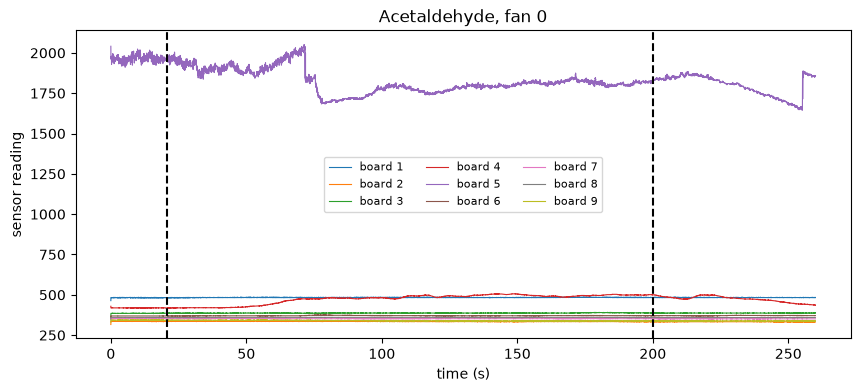

In [7]:
with zipfile.ZipFile(ZIP) as z:
    t, x, release = load_gwt.read_recording(z, meta.loc[0, "path"])   # (T_raw,), (72, T_raw)
print("raw points:", len(t), " duration:", t[-1], "s  release:", release)

fig, ax = plt.subplots(figsize=(10, 4))
for s in range(0, 72, 8):                       # first sensor of every board
    ax.plot(t, x[s], lw=0.8, label=f"board {s // 8 + 1}")
for r in release:
    ax.axvline(r, color="k", ls="--")
ax.set(xlabel="time (s)", ylabel="sensor reading", title=f"{meta.loc[0, 'gas']}, fan {meta.loc[0, 'fan']}")
ax.legend(ncol=3, fontsize=8)
plt.show()

## 4. Build X_signals: read, resample to 1500 points over 0-260 s, baseline correction

In [8]:
X = np.empty((len(meta), 72, T), dtype=np.float32)     # (600, 72, 1500)
releases = []
with zipfile.ZipFile(ZIP) as z:
    for i, path in enumerate(meta["path"]):
        t, x, release = load_gwt.read_recording(z, path)    # (T_raw,), (72, T_raw)
        X[i] = resample(x, t, T, 0.0, T_END)                 # (72, 1500)
        releases.append(release)
        if i % 100 == 0:
            print(i, end=" ")
meta["release_start"], meta["release_end"] = np.array(releases).T
meta[["release_start", "release_end"]].describe()

0 100 200 300 400 500 

,release_start,release_end
count,600.000000,600.000000
mean,20.200028,200.163618
std,0.063017,0.066606
min,20.120000,199.660000
25%,20.164750,200.139250
50%,20.198500,200.170000
75%,20.222000,200.200000
max,20.710000,200.560000


In [9]:
grid = np.linspace(0.0, T_END, T)                          # (1500,) time of every point
N_BASE = int((grid < meta["release_start"].min()).sum())   # points before the earliest release
EXPOSURE_END = int((grid < meta["release_end"].median()).sum())
print("baseline points:", N_BASE, f"({grid[N_BASE]:.1f} s)  exposure ends at point", EXPOSURE_END)

baseline_level = X[:, :, :N_BASE].mean(axis=2)             # (600, 72) resting level, kept for R2 and C5
X = baseline_correct(X, N_BASE).astype(np.float32)         # (600, 72, 1500)
assert X.shape == (600, 72, 1500) and np.isfinite(X).all()

baseline points: 116 (20.1 s)  exposure ends at point 1155


In [10]:
np.save(OUT / "X_signals.npy", X)
np.save(OUT / "baseline_level.npy", baseline_level.astype(np.float32))
meta.drop(columns=["path"]).assign(file=meta["path"]).to_csv(OUT / "meta.csv", index=False)
info = {"T": T, "n_base": N_BASE, "exposure_end": EXPOSURE_END, "dt_seconds": float(grid[1] - grid[0]),
        "location": int(LOCATION), "voltage": int(VOLTAGE), "folders": FOLDERS,
        "classes": load_gwt.GASES, "positive_class": "CO"}
with open(OUT / "info.json", "w") as f:
    json.dump(info, f, indent=1)
print("saved", X.shape, "to", OUT)

saved (600, 72, 1500) to ..\..\data\processed\gas_wind_tunnel


## 5. Look at X_signals as tables
`X_signals.npy` is a 3-D array **(600 recordings, 72 sensors, 1500 time points)**, so it cannot be one flat table.
Two views:
1. **one recording**: 1500 time points (rows) × 72 sensors (columns)
2. **all recordings**: one row per (recording, sensor) = 600 × 72 = 43,200 rows, 1500 time columns

Sensor names: `B<board>_S<sensor>`, boards 1-9, 8 sensors per board. Time is in seconds (0 to 260 s); the gas is released at about 20.2 s.

In [11]:
SENSOR_NAMES = load_gwt.SENSOR_NAMES                     # 72 names: B1_S1 ... B9_S8
time_s = np.round(grid, 2)                                 # (1500,) seconds

i = 0                                                      # pick any recording 0..599
one = pd.DataFrame(X[i].T,                                 # (1500, 72): rows = time, columns = sensors
                   index=pd.Index(time_s, name="time_s"), columns=SENSOR_NAMES)
print(f"recording {i}: {meta.loc[i, 'gas']}, fan {meta.loc[i, 'fan']}, repetition {meta.loc[i, 'rep']}  ->  {one.shape}")
one

recording 0: Acetaldehyde, fan 0, repetition 0  ->  (1500, 72)


,B1_S1,B1_S2,B1_S3,B1_S4,B1_S5,B1_S6,B1_S7,B1_S8,B2_S1,B2_S2,...,B8_S7,B8_S8,B9_S1,B9_S2,B9_S3,B9_S4,B9_S5,B9_S6,B9_S7,B9_S8
time_s,,,,,,,,,,,,,,,,,,,,,
0.00,-18.528961,-60.788269,-40.639954,-69.482971,46.644958,50.677856,49.943359,46.543518,-18.913300,-50.049255,...,35.501099,39.621521,-12.041626,-27.849701,-22.483643,-28.222717,27.320740,26.939392,30.371338,35.747559
0.17,0.471039,-1.788269,0.360046,-0.482971,1.644958,1.677856,0.943359,0.215942,0.086700,-0.049255,...,0.173523,-0.378479,-0.041626,-0.849701,0.516357,-1.222717,1.320740,0.939392,1.043762,0.747559
0.35,0.471039,-1.788269,0.360046,-0.138062,1.300049,1.022766,0.943359,0.543518,0.086700,-0.049255,...,-0.153992,-0.378479,0.303284,-0.849701,0.516357,-1.222717,0.975830,0.939392,0.371338,0.747559
0.52,0.471039,-1.788269,0.360046,-0.465637,1.644958,1.677856,0.943359,-0.439148,0.104034,-0.049255,...,0.501099,-0.378479,-0.041626,-0.849701,0.516357,-1.222717,1.320740,0.939392,0.371338,0.747559
0.69,0.471039,-1.478088,0.360046,-0.482971,1.334778,1.677856,0.633179,0.543518,0.776489,-0.049255,...,-0.498901,-0.378479,-0.041626,-0.849701,1.206177,-1.222717,1.320740,0.939392,0.371338,0.747559
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
259.31,1.160828,6.211731,4.049866,9.827240,-16.355042,-15.322144,-9.056641,-5.456482,-2.223511,-7.049255,...,-4.498901,-1.378479,-4.351837,-5.849701,-6.483643,-15.222717,-2.679260,-0.370789,0.371338,0.747559
259.48,0.471039,6.211731,3.360046,9.517029,-17.337708,-16.304810,-9.056641,-6.456482,-1.930634,-7.049255,...,-4.498901,-1.378479,-3.058960,-4.867035,-6.483643,-15.222717,-2.679260,-0.060608,0.371338,0.747559
259.65,0.471039,6.211731,3.360046,9.517029,-17.355042,-16.322144,-9.056641,-5.456482,-2.913300,-7.049255,...,-3.843811,-1.378479,-3.696716,-5.849701,-6.483643,-15.222717,-2.679260,-0.060608,0.371338,0.747559


In [17]:
rec_id = np.repeat(np.arange(len(meta)), len(SENSOR_NAMES))          # (43200,) recording of every row
X_df = pd.DataFrame(X.reshape(-1, T),                                   # (600 * 72, 1500)
                    index=pd.MultiIndex.from_arrays(
                        [rec_id, meta["gas"].to_numpy()[rec_id], meta["fan"].to_numpy()[rec_id],
                         np.tile(SENSOR_NAMES, len(meta))],
                        names=["recording", "gas", "fan", "sensor"]),
                    columns=pd.Index(time_s, name="time_s"))
print(X_df.shape)   # (43200, 1500)
X_df.head(4320)

(43200, 1500)


time_s                                0.00      0.17      0.35      0.52    \
recording gas          fan sensor                                            
0         Acetaldehyde 0   B1_S1  -18.528961  0.471039  0.471039  0.471039   
                           B1_S2  -60.788269 -1.788269 -1.788269 -1.788269   
                           B1_S3  -40.639954  0.360046  0.360046  0.360046   
                           B1_S4  -69.482971 -0.482971 -0.138062 -0.465637   
                           B1_S5   46.644958  1.644958  1.300049  1.644958   
...                                      ...       ...       ...       ...   
59        Acetaldehyde 100 B9_S4   -9.710236 -9.710236 -8.710236 -9.675537   
                           B9_S5    1.642212  2.370117  1.642212  1.642212   
                           B9_S6    1.460327  1.460327  0.770508  0.494995   
                           B9_S7    0.995056  0.995056  0.995056  0.995056   
                           B9_S8    0.680908  0.680908  0.680908  0.680908   

time_s                               0.69      0.87      1.04      1.21    \
recording gas          fan sensor                                           
0         Acetaldehyde 0   B1_S1   0.471039 -0.166718  0.471039  0.471039   
                           B1_S2  -1.478088 -1.788269 -1.322937 -0.788269   
                           B1_S3   0.360046  0.360046  0.360046  0.360046   
                           B1_S4  -0.482971  0.154785  1.051727 -0.285706   
                           B1_S5   1.334778  1.644958  1.644958  1.644958   
...                                     ...       ...       ...       ...   
59        Acetaldehyde 100 B9_S4  -8.710236 -8.710236 -8.710236 -8.710236   
                           B9_S5   1.642212  1.642212  1.642212  1.642212   
                           B9_S6   1.460327  1.460327  0.460327  1.382385   
                           B9_S7   0.995056  0.995056  0.995056  0.995056   
                           B9_S8   0.680908  0.680908  0.680908  0.680908   

time_s                               1.39      1.56    ...     258.44  \
recording gas          fan sensor                      ...              
0         Acetaldehyde 0   B1_S1   0.471039  1.023071  ...   0.471039   
                           B1_S2  -1.667847 -1.236206  ...   5.263794   
                           B1_S3   0.360046  0.360046  ...   4.307983   
                           B1_S4   0.396606 -0.035004  ...   9.517029   
                           B1_S5   0.765381  0.644958  ... -17.302979   
...                                     ...       ...  ...        ...   
59        Acetaldehyde 100 B9_S4  -8.710236 -7.713928  ...  -6.710236   
                           B9_S5   1.642212  1.642212  ...  -8.357788   
                           B9_S6   1.241394  0.460327  ...  -7.539673   
                           B9_S7   0.995056  0.995056  ...  -2.004944   
                           B9_S8   0.680908  0.680908  ...  -6.686401   

time_s                                258.61     258.79     258.96     259.13  \
recording gas          fan sensor                                               
0         Acetaldehyde 0   B1_S1    1.091461   0.471039   0.471039   0.471039   
                           B1_S2    5.211731   6.211731   6.177063   5.211731   
                           B1_S3    3.360046   3.652893   3.394714   3.360046   
                           B1_S4    9.517029   9.517029   9.517029   9.517029   
                           B1_S5  -16.975464 -16.647888 -16.389709 -16.717285   
...                                      ...        ...        ...        ...   
59        Acetaldehyde 100 B9_S4   -6.710236  -6.710236  -6.710236  -6.710236   
                           B9_S5   -8.357788  -8.357788  -8.357788  -8.357788   
                           B9_S6   -7.539673  -7.539673  -7.539673  -7.539673   
                           B9_S7   -2.004944  -2.719238  -2.004944  -2.004944   
                           B9_S8   -6.319092  -6.604797  -6.3

In [13]:
# slicing examples
print("one recording, all sensors:", X_df.loc[5].shape)                               # (72, 1500)
print("one sensor, all recordings:", X_df.xs("B1_S1", level="sensor").shape)          # (600, 1500)
print("one gas, all its recordings:", X_df.xs("CO", level="gas").shape)               # (60 * 72, 1500)
X_df.xs("B1_S1", level="sensor").head()

one recording, all sensors: (72, 1500)
one sensor, all recordings: (600, 1500)
one gas, all its recordings: (4320, 1500)


,,time_s,0.00,0.17,0.35,0.52,0.69,0.87,1.04,1.21,1.39,1.56,...,258.44,258.61,258.79,258.96,259.13,259.31,259.48,259.65,259.83,260.00
recording,gas,fan,,,,,,,,,,,,,,,,,,,,,
0,Acetaldehyde,0,-18.528961,0.471039,0.471039,0.471039,0.471039,-0.166718,0.471039,0.471039,0.471039,1.023071,...,0.471039,1.091461,0.471039,0.471039,0.471039,1.160828,0.471039,0.471039,0.471039,0.471039
1,Acetaldehyde,0,-0.015656,-0.015656,-0.015656,-0.015656,0.674133,-0.015656,-0.015656,-0.015656,-0.015656,-0.015656,...,-2.119720,-3.015656,-2.015656,-3.015656,-2.820648,-3.015656,-3.015656,-3.015656,-3.015656,-3.015656
2,Acetaldehyde,0,-0.247742,-0.247742,-0.247742,-0.213043,0.372681,-0.247742,-0.247742,-0.247742,-0.247742,0.562225,...,2.717560,2.372681,2.752258,1.752258,2.752258,3.372681,2.234924,1.752258,2.579803,2.752258
3,Acetaldehyde,0,-0.327393,0.672607,0.017517,-0.327393,0.672607,-0.327393,0.054321,0.364319,-0.086578,-0.223328,...,2.672607,2.672607,2.932343,2.672607,3.248138,3.418427,3.672607,2.672607,3.672607,2.672607
4,Acetaldehyde,0,0.713440,0.058350,0.713440,-0.286560,0.403229,0.713440,0.713440,0.713440,-0.286560,0.711578,...,3.161407,3.713440,3.713440,3.713440,3.713440,3.713440,3.713440,3.713440,3.713440,4.713440
